*  DSC530-T301 Data Exploration and Analysis
*  Weeks 7 & 8 Coding Assignment
*  Ander (Trevor) McKee

## Setup and Environment Notes

For each exercise, I restate the problem, document **which functions I use and why**, show the code with step comments and its output, then share a few notes/observations about the results.

**Environment note:** this file runs in the `pandas-book` environment that's set up with the textbook (Python 3.8, **pandas 1.2.0**, **matplotlib 3.3.2**, **seaborn 0.11.2**). There was no need for function substitutions.

In [1]:
# Imports used throughout the assignment.
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Confirm the environment.
print(f"pandas version:     {pd.__version__}")
print(f"numpy version:      {np.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"seaborn version:    {sns.__version__}")

pandas version:     1.2.0
numpy version:      1.19.5
matplotlib version: 3.3.2
seaborn version:    0.11.2


## Chapter 5 Data

The Chapter 5 exercises use the Facebook stock prices for 2018 and the earthquake data from this chapter's `data/` directory.

In [2]:
# Load Chapter 5's data.
# Convert dates to datetimes and use as index.
fb = pd.read_csv("data/fb_stock_prices_2018.csv", index_col="date", parse_dates=True)
quakes = pd.read_csv("data/earthquakes.csv")

# Confirm shape.
pd.DataFrame(
    {"rows": [fb.shape[0], quakes.shape[0]],
     "columns": [fb.shape[1], quakes.shape[1]]},
    index=["fb", "earthquakes"],
)

,rows,columns
fb,251,5
earthquakes,9332,6


# Chapter 5, Exercise 1

> Plot the rolling 20-day minimum of the Facebook closing price using pandas.

**Function notes:**
- The `D` in `.rolling("20D")` is the key letter here. If we used `.rolling(20)` instead, pandas would wait for a "full" window of 20 observations before giving a minimum. Because we specify 20 *calendar days* instead of 20 observations, pandas defaults to just 1 observation being necessary to give a minimum.
- I was curious about how many observations fall into each 20 calendar day window. Logically, in 20 days, there are about 14 weekdays, though occasionally there are holidays. The calculated counts are:

| Trading days in the window | Number of days |
| --- | ---: |
| 12 | 4 |
| 13 | 80 |
| 14 | 130 |
| 15 | 26 |
| 1–11 *(first 11 rows)* | 11 |
| **Total** | **251** |

- `.min()` here is the pandas Rolling method, not the Series method or the built-in Python function. `min(fb.close)` and `fb.close.min()` both take the column's minimum (124.06), while `Rolling.min()` returns one value per row. That's what makes the output a line.
- `.plot()` comes from `Series.plot()`, because the exercise says to use pandas. It also automatically picks up on the date-axis labeling and already has access to the index and values.

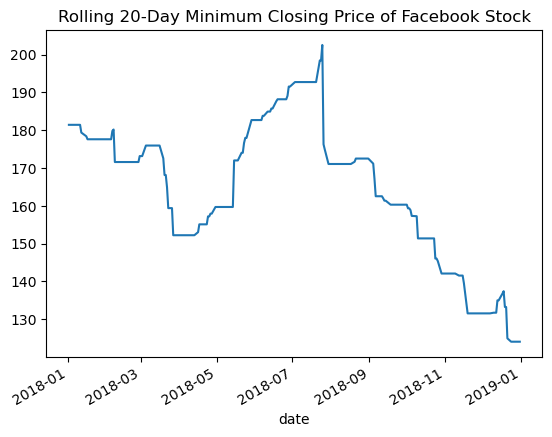

In [3]:
# fb.close selects "close" column.
# .rolling("20D") looks at today and the previous 19 calendar days.
# .min() pulls the lowest of any pulled observations.
# .plot() makes the chart.
fb.close.rolling("20D").min().plot(
    title="Rolling 20-Day Minimum Closing Price of Facebook Stock"
);

**My notes:**
- The minimum closing price in 2018 started around 182, where it then dropped through March, and then steadied in April. There was a steep peak at the end of July (202.54), then the minimum closing price continued to fall to its lowest at the end of 2018 down to about 125.
- The line moves in flat steps instead of a smooth curve. It doesn't change at all on 186 of the 250 days, and only takes 65 distinct values across the whole year. That's because the line only registers when there's a new low.
- Drops are much sharper than rises. There were about 33 downshifts and 31 upshifts. A new low registers in a moment, and there's a 20-day window for a low to drop from the record. This is why the drops are more dramatic than the rises.
- The very first point (181.42) is just that day's own closing price, and the first 11 days only have partial windows (they lack a full 20-day window).

# Chapter 5, Exercise 2

> Create a histogram and KDE of the change from open to close in the price of Facebook stock.

**Function notes:**
- The change is computed as `open - close` according to the textbook, though I initially interpreted it as `close - open`. They are mirror images around zero, so nothing changes except which side the down days land on.
- It's possible to use `plt.hist()` with `scipy.stats.gaussian_kde`, but `kind="kde"` already uses scipy underneath.
- Each plot function passes along its axes when run, so I capture it using `ax =` and pass it along to the second plot (`ax=ax`) to make sure they plot on the same axes. Unnecessary as it stands, but it'll hold up if I ever mess with this block.
- KDE is a *density function*, and the area under the curve always sums to 1. This is why I use `density=True` to achieve the same area under the curve for the histogram. Therefore, when plotted together, each plot shares the scale.
- The histogram uses matplotlib's default of **10 bins** (more bins show more texture, fewer smooth it away), and the KDE bandwidth comes from SciPy's Scott's-rule estimate (can be adjusted with `bw_method`), which controls how smooth the curve looks. I played around with them, but the defaults are best. See further notes below.

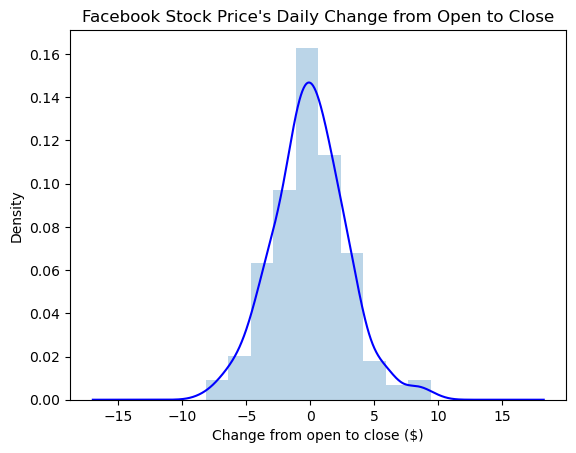

In [4]:
# Get daily change from open to close.
differential = fb.open - fb.close

# Rescale histogram to density and pass axes along.
ax = differential.plot(kind="hist", density=True, alpha=0.3)

# Draw the KDE on the same axes.
differential.plot(
    kind="kde", color="blue", ax=ax,
    title="Facebook Stock Price's Daily Change from Open to Close",
)

# Label the x-axis.
ax.set_xlabel("Change from open to close ($)");

**My notes:**
- Facebook's daily stock price tends to open and close at around the same value, with most days hovering closely around a \\$0 change.
- The histogram and KDE are mostly symmetric with a small right-skew.
- When adjusting the bandwidth higher, the curve smoothed out too much and didn't reflect the distribution. When adjusting it lower, several peaks began to appear. Scott's rule (the default) comes out to 0.3312, and reducing it manually to 0.20 produced three peaks in the curve rather than the one shown here.

It can also be done using seaborn: `sns.histplot(..., kde=True)`. I'm including this for the sake of comparison, even though seaborn is introduced in Chapter 6.

**Function notes:**
- `sns.histplot(..., kde=True)` draws both layers, where the pandas version needs `.plot()` and an `ax=ax`.
- `stat="density"` is seaborn's version of `density=True`. Left at the default `stat="count"`, seaborn rescales the KDE onto the count axis. It would read fine, but it wouldn't match the pandas plot above.
- `bins=10` matches the pandas plot. Seaborn chooses bins with a rule and would have used 16 here. 16 is fine, but I use 10 for parity.
- Seaborn clips the KDE to the range of the data (-8.18 to 9.43), while pandas pads the curve.
- Seaborn doesn't add a title, and it can't label the x-axis either because of the unnamed Series. `set_title()` and `set_xlabel()` supply those.

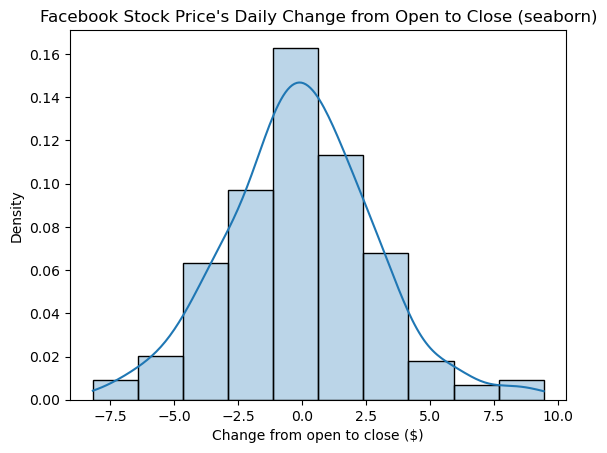

In [5]:
# stat="density" isn't as necessary, because seaborn would scale the KDE to match the histogram.
ax = sns.histplot(x=differential, kde=True, stat="density", bins=10, alpha=0.3)

# Set title and label.
ax.set_title("Facebook Stock Price's Daily Change from Open to Close (seaborn)")
ax.set_xlabel("Change from open to close ($)");

**My notes:**
- The seaborn plot includes outlines on each histogram bar, which makes the histogram much more prominent here. Seaborn also uses a subtler blue for the KDE curve. If I wanted emphasis on the histogram rather than the curve, I'd use seaborn.
- One thing I like about it as well is that the width of the x-axis is narrowed to the range of the data. There may be cases where it would be appropriate to see a KDE curve extend beyond your data, but in this case, the sharp cutoff reflects the actual observations.

# Chapter 5, Exercise 3

> Using the earthquake data, create box plots for the magnitudes of each magType used in Indonesia.

First, let's take a look at the summary stats for each type of earthquake.

In [6]:
# Parse for Indonesia.
indonesia = quakes.query("parsed_place == 'Indonesia'")[["mag", "magType"]]

# describe() gives count plus the five-number summary.
mag_stats = indonesia.groupby("magType").mag.describe()

# IQR is the height of the box.
mag_stats["IQR"] = mag_stats["75%"] - mag_stats["25%"]
mag_stats.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
magType,,,,,,,,,
mb,127.0,4.60,0.39,4.0,4.35,4.5,4.80,5.8,0.45
ms_20,1.0,5.70,NaN,5.7,5.70,5.7,5.70,5.7,0.00
mwr,1.0,4.80,NaN,4.8,4.80,4.8,4.80,4.8,0.00
mww,18.0,5.48,0.64,5.0,5.10,5.2,5.83,7.5,0.73


**My notes:**
- There is only a single count for both the ms_20 and mwr magnitude types (one recorded earthquake of each type in Indonesia!).
- Their boxplots will be flat, because there's nothing to show except the one observation.
- There is plenty of data for the mb (127) and mww (18) magnitude types, so the first and last boxplots will be plottable.

**Function notes:**
- The textbook solution uses `.groupby().boxplot()`, so this first block does the same. However, I think `df.boxplot(column="mag", by="magType")` is stronger, because all four boxplots are easily comparable on a single axes. Modified plot below.
- `query("parsed_place == 'Indonesia'")` filters to Indonesia, and then `[["mag", "magType"]]` selects just the two columns we need.
- `.boxplot()` draws the box plots, grouped by `.groupby("magType")`. `layout` just specifies a single row of 4 boxplots, and by default, pandas uses a shared y-axis with `sharey=True`.

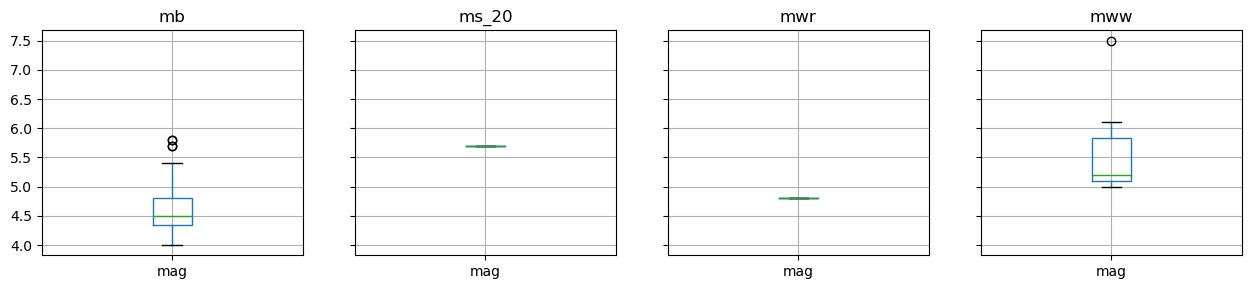

In [7]:
# Filter to Indonesia, keep only the plotted columns, then one box plot per magType.
quakes.query("parsed_place == 'Indonesia'")[["mag", "magType"]].groupby(
    "magType"
).boxplot(layout=(1, 4), figsize=(15, 3));

**Function notes:**
- `df.boxplot(column="mag", by="magType")` handles grouping internally, so by default puts the four boxplots on a single axes.
- The `.groupby().boxplot()` version above returns a pandas Series with four Axes, so I suppress the output with a semicolon. This one returns a single `AxesSubplot`, which is why I can call `ax.set_title()` on it.
- The labels have to be manually applied or there'll be overlapping titles and a missing y-axis label.
- The magnitude types come out alphabetical, since it uses `groupby()` underneath. The seaborn version needs an explicit `order=` to match.

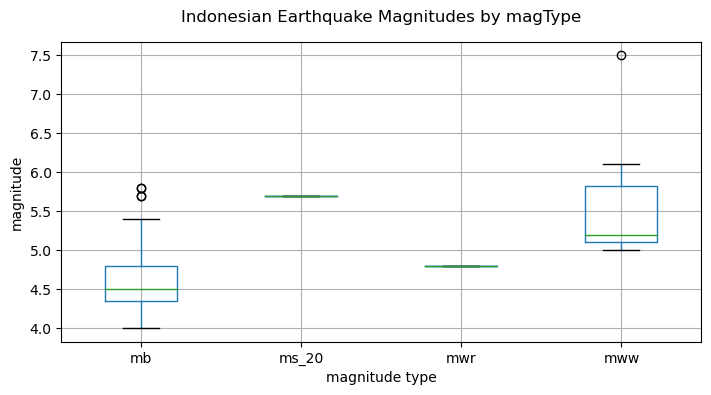

In [8]:
# Plot on a single axes.
ax = indonesia.boxplot(column="mag", by="magType", figsize=(8, 4))

# Fix titles and labels.
ax.set_title("")
plt.suptitle("Indonesian Earthquake Magnitudes by magType")
ax.set_xlabel("magnitude type")
ax.set_ylabel("magnitude");

**My notes:**
- The two magnitude types with usable data don't overlap much. The mb box runs from 4.35 to 4.80 with a median of 4.50, while the mww box sits above it, from 5.10 to 5.83 with a median of 5.20. They're measuring different parts of the range. mb is used for smaller and moderate events (best for reliability), while mww is the scale applied to the large ones.
- As expected from the summary table, ms_20 and mwr come out as horizontal lines. There's no box, no whiskers, and no spread to show.
- Both of the "real" distributions have high outliers. mb has four outliers at 5.7, 5.7, 5.8 and 5.8, and mww has one at 7.5. The 7.5 reading is the quake 78km north of Palu on September 28, 2018.
- On the single axes, the gap between the mb and mww boxes is instantly recognizable because they're adjacent. The four-panel version shares a y-axis so technically, you can make the same comparison, but it's harder to read across the panel borders.

And, like before, here is the seaborn code for comparison.

**Function notes:**
- `sns.boxplot(x="magType", y="mag", data=indonesia)` uses seaborn's long-form interface — I name the columns as strings and hand over the whole DataFrame, and seaborn does the splitting itself. That's a different approach from pandas, where I select the columns first and then call a method on the result.
- Seaborn sorts categories by **order of first appearance in the data**. Passing `sorted(...)` forces alphabetical.
- Like `df.boxplot()`, this returns a single `AxesSubplot`, so the labels can be set on it.
- The whiskers and outlier points are identical, because seaborn defaults to the 1.5x rule.
- Seaborn gives each box its own color from the default palette.

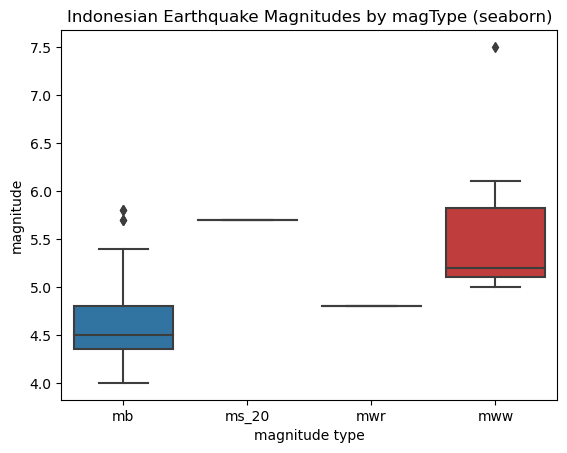

In [9]:
# order= forces alphabetical.
ax = sns.boxplot(
    x="magType", y="mag", data=indonesia,
    order=sorted(indonesia.magType.unique()),
)

ax.set_title("Indonesian Earthquake Magnitudes by magType (seaborn)")
ax.set_xlabel("magnitude type")
ax.set_ylabel("magnitude");

**My notes:**
- Seaborn fills each box with a solid color and outlines it in dark gray, where pandas leaves the boxes unfilled with a green median line. The fill makes mb and mww look solid, which makes ms_20 and mwr truly collapse into thin lines.
- Pandas turns on a y-axis grid by default and seaborn doesn't. The grid makes it easier to read a specific magnitude, while the clean version puts more emphasis on the boxes themselves.
- The outliers are drawn as diamonds here instead of open circles. I don't see a functional difference.
- This is the one I'd show someone. It puts all four types on one axis and uses filled boxes/a cleaner background to make the gap between mb and mww easier to see.

# Chapter 5, Exercise 4

> Make a line plot of the difference between the weekly maximum high price and the weekly minimum low price for Facebook. This should be a single line.

**Function notes:**
- `resample("1W")` bins the trading days into calendar weeks. `"W"` anchors weeks to Sunday (`"W" == "W-SUN"`), the bins are right-closed, and each point is labeled with the Sunday that *ends* its week.
- `.agg(dict(high="max", low="min"))` gives each column its own function: `high` takes the max, `low` takes the min. Two separate resamples would give the same answer, but you'd need to recombine the Series.
- `rolling("7D")` was considered and rejected. "Weekly" means one value per week, which is resampling, not rolling.

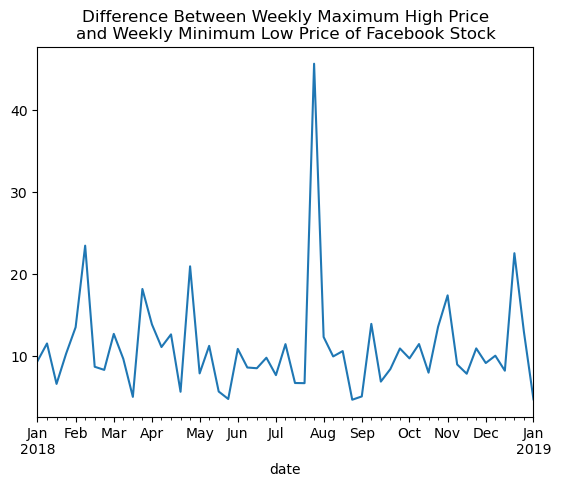

In [10]:
# Weekly bins: the max of high and the min of low within each week.
weekly = fb.resample("1W").agg(dict(high="max", low="min"))

# Subtract first so the chart draws one line.
# Plotting weekly[["high", "low"]] would draw two.
(weekly.high - weekly.low).plot(
    title="Difference Between Weekly Maximum High Price\n"
          "and Weekly Minimum Low Price of Facebook Stock"
);

**My notes:**
- In most weeks, there is a modest gap between the high and the low. The median week is \\$9.76 and the mean is \\$11.01, and most observations are between roughly \\$5 and \\$15. It implies Facebook traded in a fairly tight range week to week.
- There is a significant spike at the end of July. The spread was \\$45.62 and nearly double the second-largest week of the year (\\$23.43 in mid-February). It's the same crash in Exercise 1: the high of \\$218.62 was set on July 25 and the low of \\$173.00 two days later on July 27.
- The sharp drop at the right edge is a resampling issue. `resample("1W")` labels each bin with the Sunday that *ends* it, and the final bin only holds one trading day. It's also why the x-axis shows through 2019.
- Some weeks only have 4 days to use, which pulls a couple differences down on average.

## Chapter 6 Data

> Create the following visualizations using what we have learned so far in this book and the data from this chapter. Be sure to add titles, axis labels, and legends (where appropriate) to the plots.

Chapter 6 contains the same copies of data from Chapter 5. They are reassigned here to make use of the Chapter 6 repository.

In [11]:
# Load from ch_06/data/ per the assignment's instructions.
fb_ch6 = pd.read_csv("../ch_06/data/fb_stock_prices_2018.csv", index_col="date", parse_dates=True)
quakes_ch6 = pd.read_csv("../ch_06/data/earthquakes.csv")

# Ensure they match Ch 5's.
print(f"fb matches the ch_05 copy:     {fb.equals(fb_ch6)}")
print(f"quakes matches the ch_05 copy: {quakes.equals(quakes_ch6)}")

# Use the Chapter 6 copies.
fb, quakes = fb_ch6, quakes_ch6

fb matches the ch_05 copy:     True
quakes matches the ch_05 copy: True


# Chapter 6, Exercise 1

> Using Seaborn, create a heatmap to visualize the correlation coefficients between earthquake magnitude and whether there was a tsunami for earthquakes measured with the mb magnitude type.

**Function notes:**
- `sns.heatmap()` is a neat function. It renders the color-mapped matrix with tick labels taken from the DataFrame plus a colorbar. Matplotlib needs more explicit instructions.
- `corr()` defaults to `method="pearson"` (linear, on the raw values). The rank-based alternatives give 0.33 for `spearman` and 0.29 for `kendall`.
- `vmin=-1, vmax=1, center=0` uses the full correlation range. Left at the default, seaborn puts the colors over just the observed values, making modest associations look extreme.
- Using `center=0` defaults the color map to icefire, which makes smaller associations darker. I call `cmap="vlag"` to change it to something reasonable here.
- `annot=True` prints each coefficient in its cell.
- The colorbar is the legend. It maps each color back to a correlation value, and `sns.heatmap()` draws it automatically.

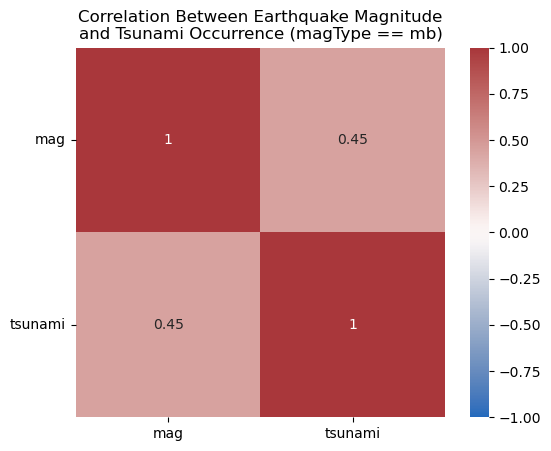

In [12]:
# Define correlation matrix of magnitude and tsunami, mb readings only.
mb_corr = quakes.query("magType == 'mb'")[["mag", "tsunami"]].corr()

# Use the full [-1, 1] correlation range and annotate.
sns.heatmap(mb_corr, annot=True, center=0, vmin=-1, vmax=1, cmap="vlag", square=True)

# Make y-labels upright, then title.
plt.yticks(rotation=0)
plt.title(
    "Correlation Between Earthquake Magnitude\n"
    "and Tsunami Occurrence (magType == mb)"
);

**My notes:**
- The correlation is 0.45, a moderate positive association: larger mb earthquakes were more often accompanied by tsunamis. The mb quakes that came with a tsunami averaged 5.30 in magnitude against 4.53 for the ones that didn't.
- To say this plainly, this problem does not warrant a correlation matrix. We are comparing two variables in one category. There is effectively one number on this plot: 0.45. A heatmap is worth it when there are several (ideally many) variables to scan at once.
- Running the same correlation across every magnitude type gives 0.26 instead of 0.45. Mixing scales makes the relationship to tsunamis less meaningful.
- Tsunamis are rare in this subset: 27 of 601 mb readings, or 4.5%. I wouldn't lean too hard on the exact value.

# Chapter 6, Exercise 2

> Create a box plot of Facebook volume traded and closing prices and draw reference lines for the bounds of a Tukey fence with a multiplier of 1.5. The bounds will be at `Q1 − (1.5 × IQR)` and `Q3 + (1.5 × IQR)`. Be sure to use the quantile() method on the data to make this easier. Pick whichever orientation you prefer for the plot, but make sure to use subplots.

**Function notes:**
- `quantile([0.25, 0.75])` returns Q1 and Q3 for both columns. It defaults to `interpolation="linear"` (this had some bite back in Weeks 3 & 4). However, with 251 rows the quartile positions land at 62.5 and 187.5, which are exactly between two sorted values. Linear interpolation at a half-step *is* the midpoint — so `linear` and `midpoint` return identical fences. The `lower`, `higher`, and `nearest` rules do shift them slightly but not enough to change the outlier count.
- Subplots are right here. Volume runs in the tens of millions of shares while the closing price sits between roughly \\$120–220. `DataFrame.plot(kind="box", subplots=True)` creates one `Axes` per column.
- I chose the vertical orientation, so the fence bounds are horizontal `axhline()`s.
- Matplotlib's whiskers already use the Tukey rule (`whis=1.5`), but whiskers snap inward to the most extreme *data point* inside the fence, while the dashed lines sit at the raw Q1 − 1.5 × IQR and Q3 + 1.5 × IQR values — so each line should land at or just beyond its whisker's end. If it doesn't, something is wrong.
- Both dashed lines are drawn on each plot, but only one has a `label=`. That way `ax.legend()` shows one "Tukey fence" entry.

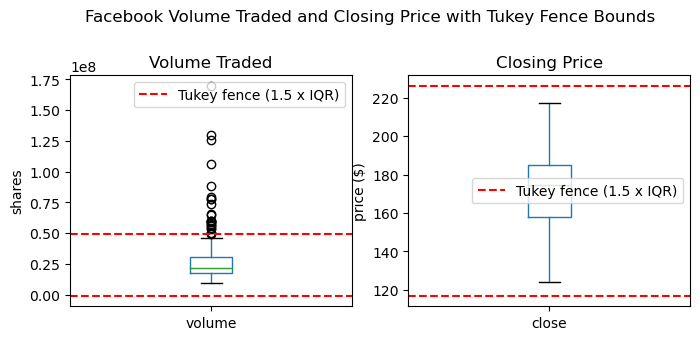

In [13]:
cols = ["volume", "close"]
subset = fb[cols]

# quantile() pulls Q1 and Q3 for both columns.
quartiles = subset.quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]

# Tukey fence bounds with a multiplier of 1.5.
lower = quartiles.loc[0.25] - 1.5 * iqr
upper = quartiles.loc[0.75] + 1.5 * iqr

# One subplot per column -- the two scales are orders of magnitude apart.
axes = subset.plot(
    kind="box", subplots=True, figsize=(8, 3),
    title=["Volume Traded", "Closing Price"],
)

# Draw both bounds on each subplot; label one line per Axes so the legend
# shows a single "Tukey fence" entry instead of two identical ones.
for ax, col, unit in zip(axes, cols, ["shares", "price ($)"]):
    ax.axhline(lower[col], color="red", linestyle="dashed", label="Tukey fence (1.5 x IQR)")
    ax.axhline(upper[col], color="red", linestyle="dashed")
    ax.set_ylabel(unit)
    ax.legend()

plt.suptitle("Facebook Volume Traded and Closing Price with Tukey Fence Bounds", y=1.1);

**My notes:**
- The two panels are opposite. Volume is heavily right-skewed with 24 days above the upper fence. Closing price is nearly symmetric and has no outliers. It only ranged from \\$124.06 to \\$217.50 across the year, while its fences land at \\$116.88 and \\$226.30.
- Volume's upper whisker stops at 45,994,800, while the dashed line sits above it at 49,042,009. That's expected, because the whisker snaps to the most extreme point inside the fence, and the dashed line marks the computed bound.
- The lower fence for volume comes out negative. It's a good reminder that the Tukey rule is arithmetic and doesn't reflect that share volume can't go below zero.
- The largest single day is July 26 at 169.8 million shares, which is the same crash that shows up in the first few exercises. The other four of the top five are March 19 through 26, when the Cambridge Analytica story broke.

## Conclusion

**July 25-26, 2018.** Four of these six exercises use Facebook stock data, and one event is central to three of them: the disappointing user-growth announcement. I was surprised it didn't show up in Exercise 2. The collapse happened overnight between the July 25 close and the July 26 open. The metric you choose determines if an event like that is visible.

**Defaults handle a lot.** Some default got turned on in almost every exercise. `rolling("20D")` versus `rolling(20)` decides whether you count calendar days or rows. `density=True` is the reason a histogram and a KDE can share a y-axis. Matplotlib picks 10 bins, while seaborn sorts categories by order of appearance and switches to a different colormap when you pass `center=`. `resample("1W")` anchors weeks to Sunday. `corr()` uses Pearson. They are reasonable assumptions, but you don't see them unless you know what you are looking for.

**Some plots still need context.** The plot in Exercise 4 looks like it ends calmly, but it's just a single trading day. The lower Tukey fence for volume sits below zero, which is impossible for a share count. Two of the four Indonesian box plots are just one observation. The heatmap only has one real number. These aren't errors or mistakes of the plots; this is just what gets produced when you go through the motions mechanically.

**pandas or seaborn.** Building both versions for Exercises 2 and 3 made me consider the trade-offs. pandas is less work when the data is already shaped, while seaborn's defaults are better tuned for presentation. For quick inspection I'd stay in pandas; for anything someone else is going to read, I'd probably use seaborn.

## References

- Molin, S. (2021). *Hands-On Data Analysis with Pandas* (2nd ed.). Packt Publishing.
- pandas 1.2.0 documentation: https://pandas.pydata.org/pandas-docs/version/1.2.0/
- seaborn 0.11 documentation: https://seaborn.pydata.org/archive/0.11/